# UML501 – Network Intrusion Detection (Step 0)
## Project Overview
This notebook performs **data loading**, **label creation**, **profiling**, and **visual exploration** for the NSL‑KDD dataset. No preprocessing or modelling is done here. All figures are saved under `figures/` as PNG (dpi = 150).


## 0.1 Load Data
* Load train and test files with column names.
* Print shape, head, dtypes.
* Show feature groups (categorical, binary, continuous).

In [14]:
import os, sys, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
sns.set_style('whitegrid')
# Column names as described in the assignment
col_names = [
    'duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land',
    'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised',
    'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells',
    'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count',
    'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate',
    'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count',
    'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate',
    'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate',
    'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate',
    'outcome', 'level'
]
# Load the datasets
train_path = os.path.join('data','raw','KDDTrain+.txt')
test_path  = os.path.join('data','raw','KDDTest+.txt')
train = pd.read_csv(train_path, header=None, names=col_names)
test  = pd.read_csv(test_path , header=None, names=col_names)
print('Train shape:', train.shape)
print('Test shape :', test.shape)
display(train.head())
print('--- dtypes ---')
print(train.dtypes)
# Feature groups
categorical = ['protocol_type','service','flag']
binary = ['land','logged_in','root_shell','su_attempted','is_host_login','is_guest_login']
continuous = [c for c in col_names if c not in categorical + binary + ['outcome','level']]
print('Feature groups:')
print('Categorical:', categorical)
print('Binary    :', binary)
print('Continuous/Count numeric (', len(continuous), '):', continuous)

Train shape: (125973, 43)
Test shape : (22544, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,outcome,level
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


--- dtypes ---
duration                         int64
protocol_type                   object
service                         object
flag                            object
src_bytes                        int64
dst_bytes                        int64
land                             int64
wrong_fragment                   int64
urgent                           int64
hot                              int64
num_failed_logins                int64
logged_in                        int64
num_compromised                  int64
root_shell                       int64
su_attempted                     int64
num_root                         int64
num_file_creations               int64
num_shells                       int64
num_access_files                 int64
num_outbound_cmds                int64
is_host_login                    int64
is_guest_login                   int64
count                            int64
srv_count                        int64
serror_rate                    float64
srv_serror

## 0.2 Labels
* Keep original attack name as `attack_name`.
* Create binary label (0 = normal, 1 = attack).
* Map attacks to high‑level categories (Normal, DoS, Probe, R2L, U2R).
* If any attack name is not in the mapping, print it and stop.
* Show counts of `attack_name`, `attack_category`, `binary_label` for train & test.

In [16]:
# Preserve original outcome
train['attack_name'] = train['outcome']
test['attack_name']  = test['outcome']
# Binary label
train['binary_label'] = (train['attack_name'] != 'normal').astype(int)
test['binary_label']  = (test['attack_name']  != 'normal').astype(int)
# Mapping to categories
dos   = ['back','land','neptune','pod','smurf','teardrop','apache2','udpstorm','processtable','mailbomb','worm']
probe = ['ipsweep','nmap','portsweep','satan','mscan','saint']
r2l   = ['ftp_write','guess_passwd','imap','multihop','phf','spy','warezclient','warezmaster','sendmail','named','snmpgetattack','snmpguess','xlock','xsnoop','httptunnel']
u2r   = ['buffer_overflow','loadmodule','perl','rootkit','ps','sqlattack','xterm']
def map_category(name):
    if name == 'normal':
        return 'Normal'
    if name in dos:   return 'DoS'
    if name in probe: return 'Probe'
    if name in r2l:   return 'R2L'
    if name in u2r:   return 'U2R'
    return None
train['attack_category'] = train['attack_name'].apply(map_category)
test['attack_category']  = test['attack_name'].apply(map_category)
unknown_train = train[train['attack_category'].isna()]['attack_name'].unique()
unknown_test  = test [test ['attack_category'].isna()]['attack_name'].unique()
if len(unknown_train) > 0 or len(unknown_test) > 0:
    print('=== UNKNOWN ATTACK NAMES DETECTED ===')
    if len(unknown_train)>0:
        print('Train unknown:', unknown_train)
    if len(unknown_test)>0:
        print('Test unknown :', unknown_test)
    sys.exit('Please provide mapping for the above attack names before proceeding.')
def show_counts(df, name):
    print(f'--- {name} ---')
    print('Attack name distribution:')
    print(df['attack_name'].value_counts().head())
    print('Attack category distribution:')
    print(df['attack_category'].value_counts())
    print('Binary label distribution:')
    print(df['binary_label'].value_counts())
show_counts(train, 'Train')
show_counts(test , 'Test')

--- Train ---
Attack name distribution:
attack_name
normal       67343
neptune      41214
satan         3633
ipsweep       3599
portsweep     2931
Name: count, dtype: int64
Attack category distribution:
attack_category
Normal    67343
DoS       45927
Probe     11656
R2L         995
U2R          52
Name: count, dtype: int64
Binary label distribution:
binary_label
0    67343
1    58630
Name: count, dtype: int64
--- Test ---
Attack name distribution:
attack_name
normal          9711
neptune         4657
guess_passwd    1231
mscan            996
warezmaster      944
Name: count, dtype: int64
Attack category distribution:
attack_category
Normal    9711
DoS       7460
R2L       2885
Probe     2421
U2R         67
Name: count, dtype: int64
Binary label distribution:
binary_label
1    12833
0     9711
Name: count, dtype: int64


## 0.3 Profile (no modifications)
* Missing values per column.
* Duplicate rows count.
* Descriptive statistics for numeric columns (transposed).
* Columns with a single unique value.
* Columns where one value covers > 99 % of rows (exact counts).
* Unique values for `protocol_type`, `service`, `flag` in train vs test (and any test‑only categories).
* Attack names present only in the test set (with counts).
* Interpretation of data‑quality observations.

In [17]:
def profile(df, name):
    print(f'--- Profiling {name} ---')

    # Missing values
    missing = df.isnull().sum()
    print('Missing values per column:')
    print(missing[missing > 0])

    # Duplicates
    dup_cnt = df.duplicated().sum()
    print('Duplicate rows:', dup_cnt)

    # Summary statistics for numeric columns
    numeric_cols = df.select_dtypes(include=[np.number]).columns
    desc = df[numeric_cols].describe().T
    display(desc)

    # Columns with a single unique value
    uniq_counts = df.nunique()
    single = uniq_counts[uniq_counts == 1].index.tolist()
    print('Columns with a single unique value:', single)

    # Near-constant columns (one value covers more than 99% of rows)
    near_const = []
    for col in df.columns:
        vc = df[col].value_counts()
        if not vc.empty and vc.iloc[0] > 0.99 * len(df):
            near_const.append((col, vc.iloc[0], vc.index[0]))

    if near_const:
        print('Columns where one value >99% of rows (value, count):')
        for col, cnt, val in near_const:
            print(f'  {col}: {val!r} appears {cnt} times')
    else:
        print('No near-constant columns (>99%).')

    print('\nInterpretation: (see markdown cell below)')


def compare_train_test(train, test):
    print('--- Train vs Test comparison ---')

    # Categorical columns: unique values and test-only categories
    for cat in ['protocol_type', 'service', 'flag']:
        train_uniq = set(train[cat].unique())
        test_uniq = set(test[cat].unique())
        print(f'Unique values for {cat}: train={len(train_uniq)}, test={len(test_uniq)}')
        extra = test_uniq - train_uniq
        if extra:
            print('  Categories present only in test:', extra)

    # Attack names that appear only in the test set
    train_att = set(train['attack_name'].unique())
    test_att = set(test['attack_name'].unique())
    only_test = test_att - train_att

    if only_test:
        print('\nAttack names present only in test set:')
        for att in sorted(only_test):
            cnt = (test['attack_name'] == att).sum()
            print(f'  {att}: {cnt} rows')
    else:
        print('All test attack names also appear in train.')


profile(train, 'Train')
profile(test, 'Test')
compare_train_test(train, test)

--- Profiling Train ---
Missing values per column:
Series([], dtype: int64)
Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
duration,125973.0,287.144650,2.604515e+03,0.0,0.00,0.00,0.00,4.290800e+04
src_bytes,125973.0,45566.743000,5.870331e+06,0.0,0.00,44.00,276.00,1.379964e+09
dst_bytes,125973.0,19779.114421,4.021269e+06,0.0,0.00,0.00,516.00,1.309937e+09
land,125973.0,0.000198,1.408607e-02,0.0,0.00,0.00,0.00,1.000000e+00
wrong_fragment,125973.0,0.022687,2.535300e-01,0.0,0.00,0.00,0.00,3.000000e+00
urgent,125973.0,0.000111,1.436603e-02,0.0,0.00,0.00,0.00,3.000000e+00
hot,125973.0,0.204409,2.149968e+00,0.0,0.00,0.00,0.00,7.700000e+01
num_failed_logins,125973.0,0.001222,4.523914e-02,0.0,0.00,0.00,0.00,5.000000e+00
logged_in,125973.0,0.395736,4.890101e-01,0.0,0.00,0.00,1.00,1.000000e+00
num_compromised,125973.0,0.279250,2.394204e+01,0.0,0.00,0.00,0.00,7.479000e+03


Columns with a single unique value: ['num_outbound_cmds']
Columns where one value >99% of rows (value, count):
  land: np.int64(0) appears 125948 times
  wrong_fragment: np.int64(0) appears 124883 times
  urgent: np.int64(0) appears 125964 times
  num_failed_logins: np.int64(0) appears 125851 times
  root_shell: np.int64(0) appears 125804 times
  su_attempted: np.int64(0) appears 125893 times
  num_root: np.int64(0) appears 125324 times
  num_file_creations: np.int64(0) appears 125686 times
  num_shells: np.int64(0) appears 125926 times
  num_access_files: np.int64(0) appears 125602 times
  num_outbound_cmds: np.int64(0) appears 125973 times
  is_host_login: np.int64(0) appears 125972 times
  is_guest_login: np.int64(0) appears 124786 times

Interpretation: (see markdown cell below)
--- Profiling Test ---
Missing values per column:
Series([], dtype: int64)
Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
duration,22544.0,218.859076,1407.176612,0.0,0.00,0.00,0.0000,57715.0
src_bytes,22544.0,10395.450231,472786.431088,0.0,0.00,54.00,287.0000,62825648.0
dst_bytes,22544.0,2056.018808,21219.297609,0.0,0.00,46.00,601.0000,1345927.0
land,22544.0,0.000311,0.017619,0.0,0.00,0.00,0.0000,1.0
wrong_fragment,22544.0,0.008428,0.142599,0.0,0.00,0.00,0.0000,3.0
urgent,22544.0,0.000710,0.036473,0.0,0.00,0.00,0.0000,3.0
hot,22544.0,0.105394,0.928428,0.0,0.00,0.00,0.0000,101.0
num_failed_logins,22544.0,0.021647,0.150328,0.0,0.00,0.00,0.0000,4.0
logged_in,22544.0,0.442202,0.496659,0.0,0.00,0.00,1.0000,1.0
num_compromised,22544.0,0.119899,7.269597,0.0,0.00,0.00,0.0000,796.0


Columns with a single unique value: ['num_outbound_cmds']
Columns where one value >99% of rows (value, count):
  land: np.int64(0) appears 22537 times
  wrong_fragment: np.int64(0) appears 22444 times
  urgent: np.int64(0) appears 22534 times
  root_shell: np.int64(0) appears 22489 times
  su_attempted: np.int64(0) appears 22540 times
  num_root: np.int64(0) appears 22496 times
  num_file_creations: np.int64(0) appears 22502 times
  num_shells: np.int64(0) appears 22525 times
  num_access_files: np.int64(0) appears 22472 times
  num_outbound_cmds: np.int64(0) appears 22544 times
  is_host_login: np.int64(0) appears 22533 times

Interpretation: (see markdown cell below)
--- Train vs Test comparison ---
Unique values for protocol_type: train=3, test=3
Unique values for service: train=70, test=64
Unique values for flag: train=11, test=11

Attack names present only in test set:
  apache2: 737 rows
  httptunnel: 133 rows
  mailbomb: 293 rows
  mscan: 996 rows
  named: 17 rows
  processtable

**Interpretation**
*Summarise key observations from the profiling step.*

## 0.4 Visualisation (figures saved to `figures/`)

In [18]:
os.makedirs('figures', exist_ok=True)
normal_color = '#4c72b0'
attack_color = '#c44e52'
label_map = {0: 'normal', 1: 'attack'}

### Figure 1 – Class Balance (binary_label) for Train & Test

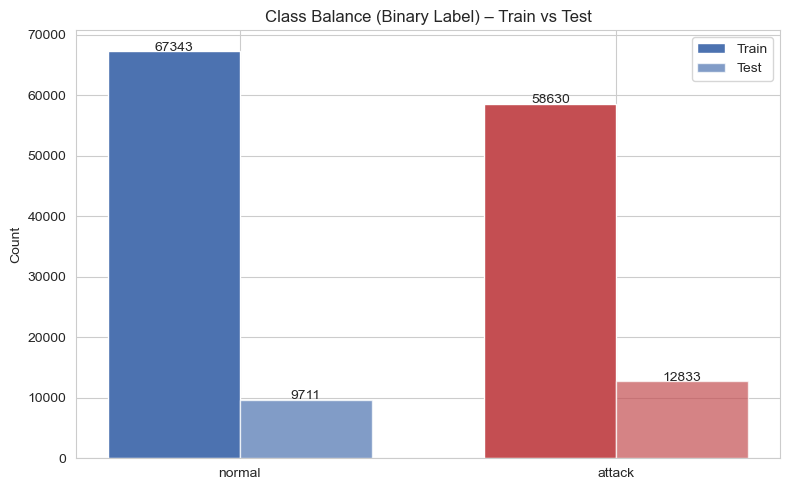

In [19]:
fig, ax = plt.subplots(figsize=(8,5))
counts_train = train['binary_label'].value_counts().sort_index()
counts_test  = test ['binary_label'].value_counts().sort_index()
labels = ['normal','attack']
x = np.arange(len(labels))
width = 0.35
ax.bar(x - width/2, counts_train, width, label='Train', color=[normal_color, attack_color])
ax.bar(x + width/2, counts_test , width, label='Test' , color=[normal_color, attack_color], alpha=0.7)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('Count')
ax.set_title('Class Balance (Binary Label) – Train vs Test')
ax.legend()
for i, cnt in enumerate(counts_train):
    ax.text(i - width/2, cnt+5, str(cnt), ha='center')
for i, cnt in enumerate(counts_test):
    ax.text(i + width/2, cnt+5, str(cnt), ha='center')
plt.tight_layout()
plt.savefig('figures/fig01_class_balance.png', dpi=150)
plt.show()

**Interpretation**
The bar chart shows the absolute counts of normal vs attack records in both train and test sets, highlighting any class imbalance that will affect later modelling choices.